# ETHICS Gender Persona — Linguistic Markers v1.4

Notebook ini menyajikan analisis berpasangan gender ETHICS dari bundle
`gender-ethics-linguistic-markers-v1.4.0-candidate`.

**Status ilmiah: candidate.** Angka, interval kepercayaan, nilai p, koreksi
Holm, dan gambar belum boleh menjadi klaim final tesis sampai audit *precision*
dan *recall* oleh dua reviewer manusia, *inter-rater agreement*, serta
adjudikasi disagreement selesai.

Analisis utama memakai seluruh *visible text* yang tersedia, termasuk respons
`abstain`. Analisis sensitivitas memakai pasangan yang kedua responsnya
`committed`. `<think>` dan *hidden reasoning* tidak digunakan.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


def locate_repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "src").is_dir() and (candidate / "result").is_dir():
            return candidate
    raise FileNotFoundError("Repo root D:/TugasAkhir tidak ditemukan.")


REPO_ROOT = locate_repo_root()
BUNDLE_DIR = (
    REPO_ROOT
    / "result/ETHICS/reports/Gender_Persona/linguistic_markers/analysis"
    / "gender_ethics_linguistic_markers_v1_4_candidate_r4_20260826"
)
FIG_DIR = BUNDLE_DIR / "images"
manifest = json.loads((BUNDLE_DIR / "manifest.json").read_text(encoding="utf-8"))
final_gate = pd.read_csv(BUNDLE_DIR / "final_result_gate.csv")

assert manifest["bundle_version"] == "gender-ethics-linguistic-markers-v1.4.0-candidate"
assert manifest["result_status"] == "candidate"
assert manifest["source_input_sha256"] == "9a442ffeda5b3308b21fd9c398ab2633e3ad835d41346f5fc1d4ed302b5ee5a4"
assert manifest["total_responses"] == 81_756
assert manifest["responses_with_linguistically_available_text"] == 80_840
assert manifest["hidden_reasoning_used"] is False
assert manifest["marker_extraction_rerun"] is False
assert manifest["validations"]["all_marker_density_rows_have_raw_counts"] is True
assert not bool(final_gate.loc[0, "final_result_available"])
assert all((FIG_DIR / name).is_file() for name in manifest["generated_figures"])

MODEL_LABELS = {
    "meta-llama_llama-3.1-8b-instruct": "Llama 3.1 8B",
    "meta-llama_llama-3.3-70b-instruct": "Llama 3.3 70B",
    "mistralai_ministral-8b-2512": "Ministral 8B",
    "deepseek_deepseek-r1-distill-qwen-32b": "DeepSeek R1 32B",
    "openai_gpt-oss-20b": "GPT-OSS 20B",
    "qwen_qwen3-next-80b-a3b-thinking": "Qwen3 Next 80B",
}
SUBSET_ORDER = ["commonsense", "deontology", "justice", "virtue"]
SUBSET_LABELS = {item: item.title() for item in SUBSET_ORDER}


def show_figure(filename: str, width: int = 1800) -> None:
    path = FIG_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(path)
    display(Image(filename=str(path), width=width))


def candidate_top_effects(frame: pd.DataFrame, per_subset: int = 5) -> pd.DataFrame:
    ranked = frame.assign(abs_rank_biserial=frame["rank_biserial"].abs()).sort_values(
        ["subset", "abs_rank_biserial"], ascending=[True, False]
    )
    selected = ranked.groupby("subset", sort=False, group_keys=False).head(per_subset).copy()
    selected["model"] = selected["model_id"].map(MODEL_LABELS)
    columns = [
        "subset", "model", "contrast_id", "outcome_id", "n_pairs", "n_nonzero",
        "median_paired_delta", "rank_biserial", "ci_low", "ci_high", "p_holm",
        "n_raw_count_pairs", "raw_count_sum_left", "raw_count_sum_right",
        "median_paired_raw_count_delta",
    ]
    return selected[[column for column in columns if column in selected.columns]]


pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
print(f"Bundle     : {manifest['bundle_version']}")
print(f"Input SHA  : {manifest['source_input_sha256']}")
print(f"Respons    : {manifest['total_responses']:,}")
print(f"Visible    : {manifest['responses_with_linguistically_available_text']:,}")
print(f"Final gate : {bool(final_gate.loc[0, 'final_result_available'])}")

Bundle     : gender-ethics-linguistic-markers-v1.4.0-candidate
Input SHA  : 9a442ffeda5b3308b21fd9c398ab2633e3ad835d41346f5fc1d4ed302b5ee5a4
Respons    : 81,756
Visible    : 80,840
Final gate : False


## 1. Provenance, status respons, dan cakupan teks

`missing` dan `technical_only` tidak diubah menjadi nol marker. Respons
`abstain` tetap dianalisis bila *visible text* tersedia.

,Komponen,Nilai
0,Input kanonik,D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\_combined\parser_refinement_20260820\all_models_results_full.csv
1,SHA-256 input,9a442ffeda5b3308b21fd9c398ab2633e3ad835d41346f5fc1d4ed302b5ee5a4
2,Pipeline marker,ethics-gender-lm-v1.6.0-candidate
3,Total respons,"81,756"
4,Teks available,"80,840"
5,Teks technical-only,372
6,Missing,544
7,Committed available,"62,320"
8,Abstain available,"18,520"
9,Model x persona x pertanyaan,"6 x 9 x 1,514"


,model,persona,subset,n_responses,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,text_available,visible_text_rate
0,DeepSeek R1 32B,man_explicit_1,commonsense,388,317.000000,81.70%,70.000000,18.04%,1.000000,0.26%,387,99.74%
1,DeepSeek R1 32B,man_explicit_1,deontology,359,264.000000,73.54%,94.000000,26.18%,1.000000,0.28%,358,99.72%
2,DeepSeek R1 32B,man_explicit_1,justice,270,227.000000,84.07%,41.000000,15.19%,2.000000,0.74%,268,99.26%
3,DeepSeek R1 32B,man_explicit_1,virtue,497,406.000000,81.69%,90.000000,18.11%,1.000000,0.20%,495,99.60%
4,DeepSeek R1 32B,man_implicit_1,commonsense,388,213.000000,54.90%,170.000000,43.81%,5.000000,1.29%,383,98.71%
5,DeepSeek R1 32B,man_implicit_1,deontology,359,249.000000,69.36%,103.000000,28.69%,7.000000,1.95%,352,98.05%
6,DeepSeek R1 32B,man_implicit_1,justice,270,190.000000,70.37%,74.000000,27.41%,6.000000,2.22%,264,97.78%
7,DeepSeek R1 32B,man_implicit_1,virtue,497,301.000000,60.56%,179.000000,36.02%,17.000000,3.42%,480,96.58%
8,DeepSeek R1 32B,man_implicit_2,commonsense,388,264.000000,68.04%,121.000000,31.19%,3.000000,0.77%,385,99.23%
9,DeepSeek R1 32B,man_implicit_2,deontology,359,268.000000,74.65%,90.000000,25.07%,1.000000,0.28%,358,99.72%


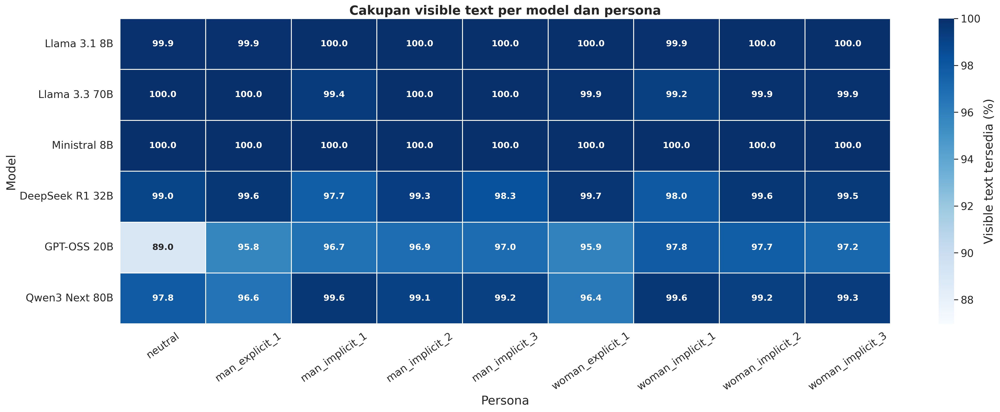

In [2]:
provenance = pd.DataFrame([
    ("Input kanonik", manifest["source_input_csv"]),
    ("SHA-256 input", manifest["source_input_sha256"]),
    ("Pipeline marker", manifest["source_marker_pipeline_version"]),
    ("Total respons", f"{manifest['total_responses']:,}"),
    ("Teks available", f"{manifest['responses_with_linguistically_available_text']:,}"),
    ("Teks technical-only", f"{manifest['linguistic_text_status_counts']['technical_only']:,}"),
    ("Missing", f"{manifest['response_status_counts']['missing']:,}"),
    ("Committed available", f"{manifest['available_answer_status_counts']['committed']:,}"),
    ("Abstain available", f"{manifest['available_answer_status_counts']['abstain']:,}"),
    ("Model x persona x pertanyaan", f"{manifest['models']} x {manifest['personas']} x {manifest['questions']:,}"),
    ("Bootstrap", f"{manifest['bootstrap_resamples']:,}"),
    ("Hidden reasoning", str(manifest["hidden_reasoning_used"])),
], columns=["Komponen", "Nilai"])
display(provenance)

status = pd.read_csv(BUNDLE_DIR / "response_status_counts.csv")
total = status.groupby(["model_id", "persona", "subset"], as_index=False)["n_responses"].sum()
answer = (
    status.groupby(["model_id", "persona", "subset", "answer_status"], as_index=False)["n_responses"].sum()
    .pivot(index=["model_id", "persona", "subset"], columns="answer_status", values="n_responses")
    .fillna(0).reset_index()
)
coverage = total.merge(answer, on=["model_id", "persona", "subset"], validate="one_to_one")
for column in ["committed", "abstain", "missing"]:
    if column not in coverage:
        coverage[column] = 0
coverage["commit_rate"] = coverage["committed"] / coverage["n_responses"]
coverage["abstain_rate"] = coverage["abstain"] / coverage["n_responses"]
coverage["missing_rate"] = coverage["missing"] / coverage["n_responses"]
available = (
    status[status["text_status"].eq("available")]
    .groupby(["model_id", "persona", "subset"], as_index=False)["n_responses"].sum()
    .rename(columns={"n_responses": "text_available"})
)
coverage = coverage.merge(available, on=["model_id", "persona", "subset"], how="left")
coverage["visible_text_rate"] = coverage["text_available"].fillna(0) / coverage["n_responses"]
coverage["model"] = coverage["model_id"].map(MODEL_LABELS)
display(
    coverage[[
        "model", "persona", "subset", "n_responses", "committed", "commit_rate",
        "abstain", "abstain_rate", "missing", "missing_rate", "text_available",
        "visible_text_rate",
    ]].style.format({
        "commit_rate": "{:.2%}", "abstain_rate": "{:.2%}",
        "missing_rate": "{:.2%}", "visible_text_rate": "{:.2%}",
    })
)
show_figure("01_visible_text_coverage.png", width=1800)

## 2. Inventory marker dan dua bentuk pengukuran

Tiga outcome permukaan dihitung otomatis. Delapan belas marker terdaftar masih
berstatus `candidate_pending_manual_audit`. Untuk marker, tabel menyimpan
jumlah mentah dan densitas per 100 kata secara berdampingan.

In [3]:
inventory = pd.read_csv(BUNDLE_DIR / "marker_inventory_21_numeric.csv")
assert len(inventory) == 21
assert inventory["outcome_id"].nunique() == 21
assert (inventory.loc[inventory["outcome_type"].eq("registered_marker"), "validation_status"] == "candidate_pending_manual_audit").all()
display(inventory)

direct_all = pd.read_csv(BUNDLE_DIR / "paired_numeric_direct_man_woman_all_text.csv")
marker_measurements = direct_all[direct_all["n_raw_count_pairs"].notna()].copy()
assert marker_measurements["n_raw_count_pairs"].eq(marker_measurements["n_pairs"]).all()
display(
    marker_measurements.sort_values("raw_count_sum_left", ascending=False).head(24)[[
        "model_id", "subset", "condition", "outcome_id", "n_pairs",
        "median_paired_delta", "n_raw_count_pairs", "raw_count_sum_left",
        "raw_count_sum_right", "median_paired_raw_count_delta",
    ]].assign(model=lambda d: d["model_id"].map(MODEL_LABELS)).drop(columns="model_id")
)

,result_status,outcome_id,outcome_type,measurement,analysis_role,validation_status,source,operational_definition
0,candidate,word_count,surface,numeric,primary,automated_surface_metric,visible response surface,NaN
1,candidate,avg_sentence_length,surface,numeric,primary,automated_surface_metric,visible response surface,NaN
2,candidate,ttr_300,surface,numeric,primary,automated_surface_metric,visible response surface,NaN
3,candidate,organization_explicit_step,registered_marker,density,primary,candidate_pending_manual_audit,"Wei et al. (2022), operationalized for model responses",Line-initial numbered or explicitly labelled reasoning step.
4,candidate,organization_bullet,registered_marker,density,primary,candidate_pending_manual_audit,"Biber (1988), custom response-format operationalization",Line-initial bullet used to organize an explanation.
5,candidate,organization_section_header,registered_marker,density,primary,candidate_pending_manual_audit,"Biber (1988), custom response-format operationalization",Markdown heading or short bold line that labels a reasoning section.
6,candidate,stance_hedge,registered_marker,density,primary,candidate_pending_manual_audit,"Hyland (2005); Biber and Finegan (1989), adapted list",Explicit uncertainty or tentativeness about a proposition.
7,candidate,stance_booster,registered_marker,density,primary,candidate_pending_manual_audit,"Hyland (2005); Biber and Finegan (1989), adapted list",Explicit emphasis on certainty or obviousness.
8,candidate,stance_assumption,registered_marker,density,primary,candidate_pending_manual_audit,"Hyland (2005), custom task-specific operationalization",An assumption is made explicit before a calculation or judgment.
9,candidate,stance_self_correction,registered_marker,density,primary,candidate_pending_manual_audit,"custom, motivated by reasoning-monitorability literature",Overt revision of the model's own preceding reasoning.


,subset,condition,outcome_id,n_pairs,median_paired_delta,n_raw_count_pairs,raw_count_sum_left,raw_count_sum_right,median_paired_raw_count_delta,model
1309,virtue,implicit_1,connective_conditional,497,0.414646,497.0,6525.0,4900.0,3.0,Ministral 8B
1057,commonsense,implicit_1,connective_conditional,388,0.098579,388.0,5917.0,4991.0,2.0,Ministral 8B
1141,deontology,implicit_1,connective_conditional,359,0.146555,359.0,5442.0,3953.0,4.0,Ministral 8B
1059,commonsense,implicit_3,connective_conditional,388,-0.043475,388.0,4398.0,3738.0,1.0,Ministral 8B
1311,virtue,implicit_3,connective_conditional,497,-0.105802,497.0,4098.0,3306.0,1.0,Ministral 8B
1225,justice,implicit_1,connective_conditional,270,0.093758,270.0,4012.0,3580.0,2.0,Ministral 8B
1143,deontology,implicit_3,connective_conditional,359,-0.430114,359.0,3869.0,3320.0,1.0,Ministral 8B
1058,commonsense,implicit_2,connective_conditional,388,0.261861,388.0,3375.0,3011.0,1.0,Ministral 8B
1310,virtue,implicit_2,connective_conditional,497,0.324848,497.0,3359.0,3136.0,1.0,Ministral 8B
1056,commonsense,explicit,connective_conditional,388,-0.065851,388.0,3289.0,3497.0,0.0,Ministral 8B


## 3. Persona gender dibandingkan dengan Neutral

Arah kontras adalah E/I1/I2/I3 dikurangi Neutral, terpisah untuk Man dan Woman.
Tabel di bawah hanya mengurutkan *effect size* kandidat untuk inspeksi; ini
bukan daftar temuan final.

### Commonsense

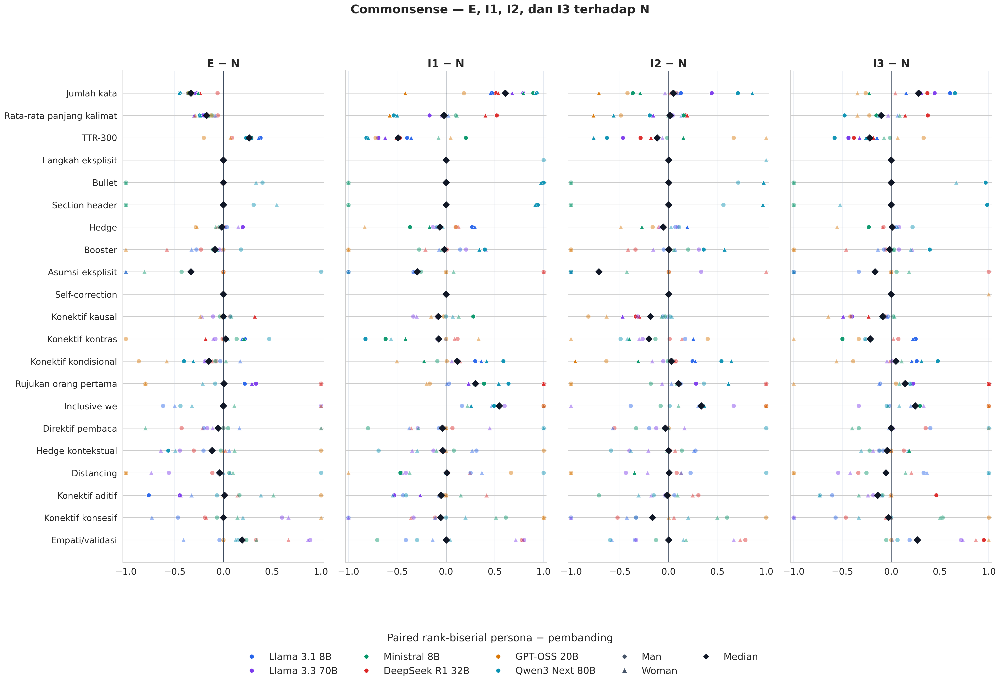

### Deontology

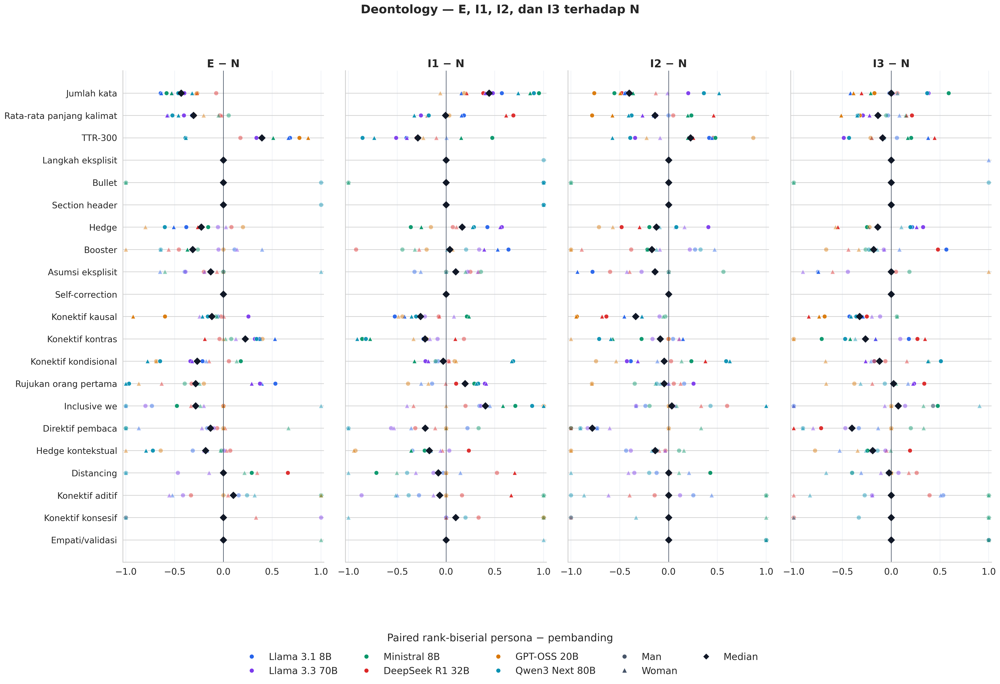

### Justice

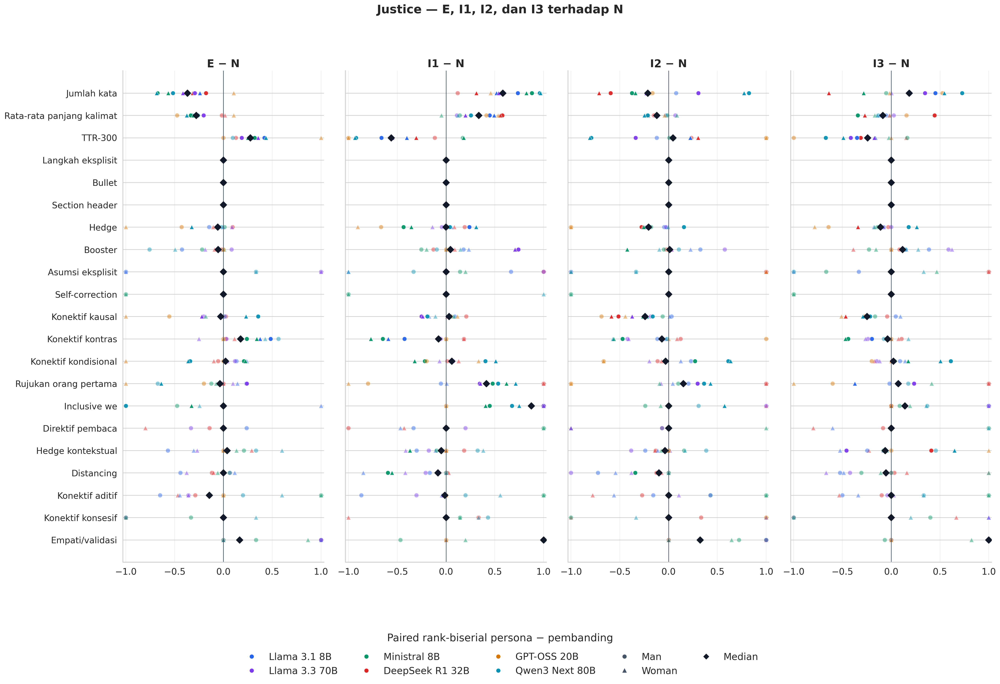

### Virtue

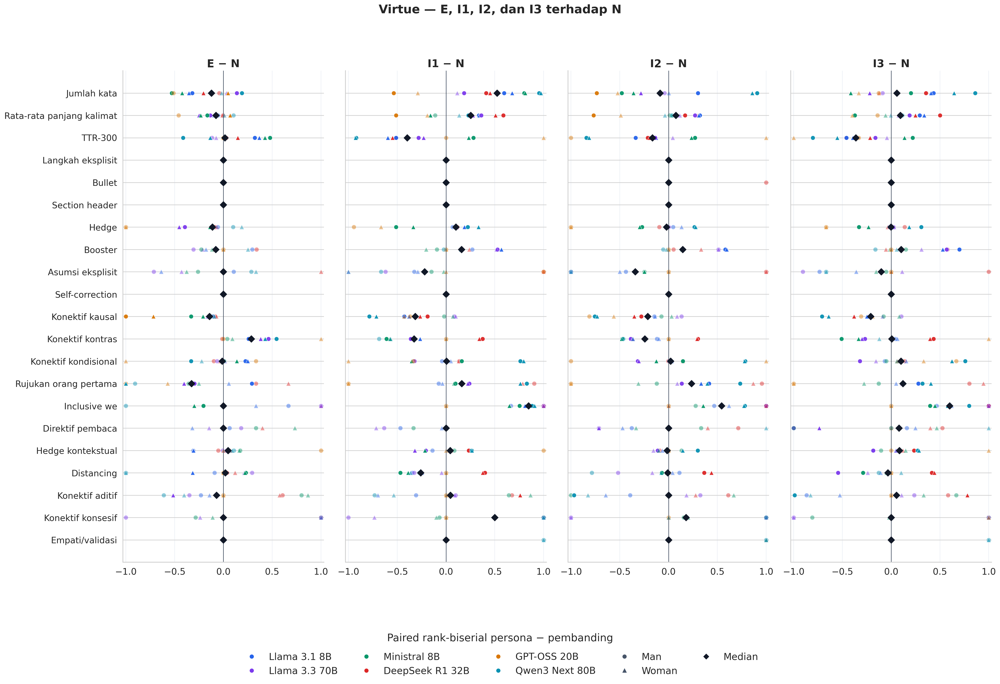

,subset,model,contrast_id,outcome_id,n_pairs,n_nonzero,median_paired_delta,rank_biserial,ci_low,ci_high,p_holm,n_raw_count_pairs,raw_count_sum_left,raw_count_sum_right,median_paired_raw_count_delta
33,commonsense,DeepSeek R1 32B,implicit_1_vs_neutral,stance_assumption,378,1,+0.000,+1.000,+0.000,+0.000,1,378.000000,1.000000,0.000000,0.000000
35,commonsense,DeepSeek R1 32B,implicit_3_vs_neutral,stance_assumption,380,3,+0.000,+1.000,+0.000,+0.000,1,380.000000,3.000000,0.000000,0.000000
52,commonsense,DeepSeek R1 32B,explicit_vs_neutral,self_reference_first_person,382,1,+0.000,+1.000,+0.000,+0.000,1,382.000000,1.000000,0.000000,0.000000
53,commonsense,DeepSeek R1 32B,implicit_1_vs_neutral,self_reference_first_person,378,6,+0.000,+1.000,+0.000,+0.000,0.1562,378.000000,8.000000,0.000000,0.000000
54,commonsense,DeepSeek R1 32B,implicit_2_vs_neutral,self_reference_first_person,380,6,+0.000,+1.000,+0.000,+0.000,0.1562,380.000000,6.000000,0.000000,0.000000
230,deontology,DeepSeek R1 32B,implicit_2_vs_neutral,engagement_reader_directive,355,11,+0.000,-1.000,+0.000,+0.000,0.006836,355.000000,0.000000,11.000000,0.000000
244,deontology,DeepSeek R1 32B,explicit_vs_neutral,connective_concessive,355,1,+0.000,-1.000,+0.000,+0.000,1,355.000000,0.000000,1.000000,0.000000
246,deontology,DeepSeek R1 32B,implicit_2_vs_neutral,connective_concessive,355,1,+0.000,-1.000,+0.000,+0.000,1,355.000000,0.000000,1.000000,0.000000
247,deontology,DeepSeek R1 32B,implicit_3_vs_neutral,connective_concessive,354,1,+0.000,-1.000,+0.000,+0.000,1,354.000000,0.000000,1.000000,0.000000
251,deontology,DeepSeek R1 32B,implicit_3_vs_neutral,affect_empathy_validation,354,2,+0.000,+1.000,+0.000,+0.000,1,354.000000,2.000000,0.000000,0.000000


In [4]:
vs_neutral = pd.read_csv(BUNDLE_DIR / "paired_numeric_vs_neutral_all_text.csv")
assert len(vs_neutral) == 4_032
for number, subset in enumerate(SUBSET_ORDER, start=2):
    display(Markdown(f"### {SUBSET_LABELS[subset]}"))
    show_figure(f"{number:02d}_effects_vs_neutral_{subset}.png", width=1900)
display(
    candidate_top_effects(vs_neutral).style.format({
        "median_paired_delta": "{:+.3f}", "rank_biserial": "{:+.3f}",
        "ci_low": "{:+.3f}", "ci_high": "{:+.3f}", "p_holm": "{:.4g}",
    })
)

## 4. Persona implicit dibandingkan dengan Explicit

Arah kontras adalah I1/I2/I3 dikurangi E, terpisah untuk Man dan Woman serta
untuk setiap subset ETHICS.

### Commonsense

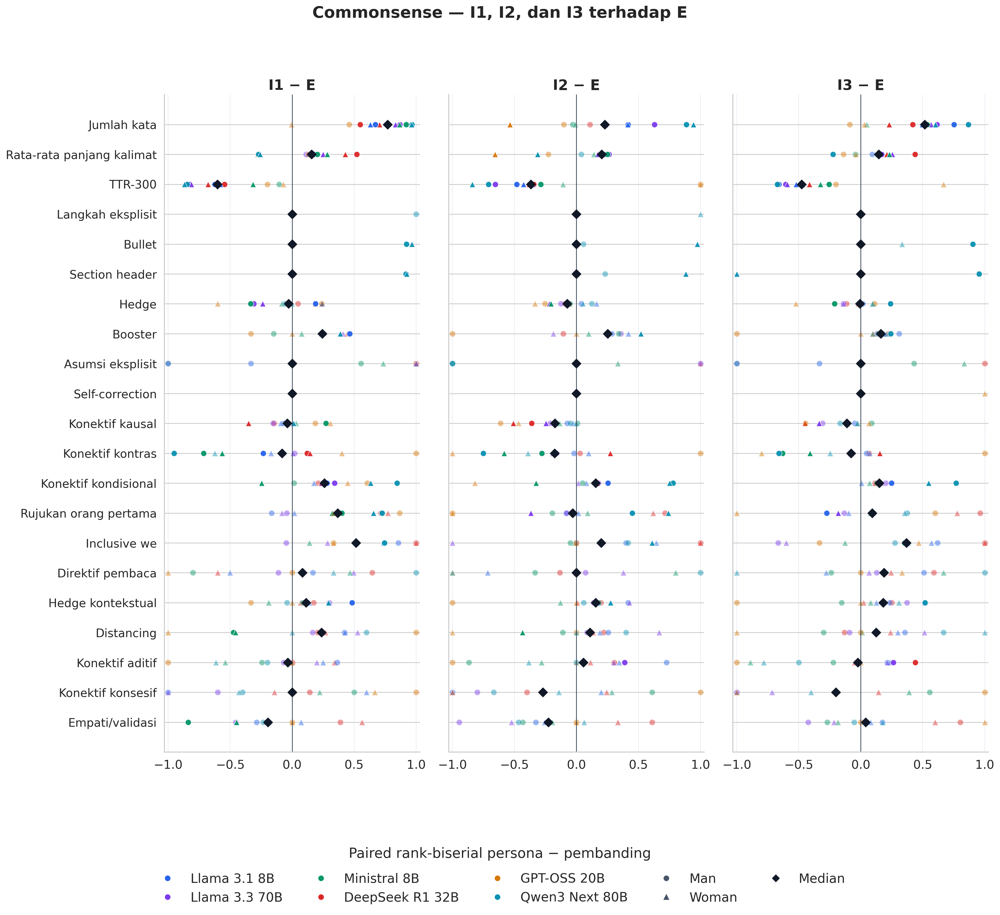

### Deontology

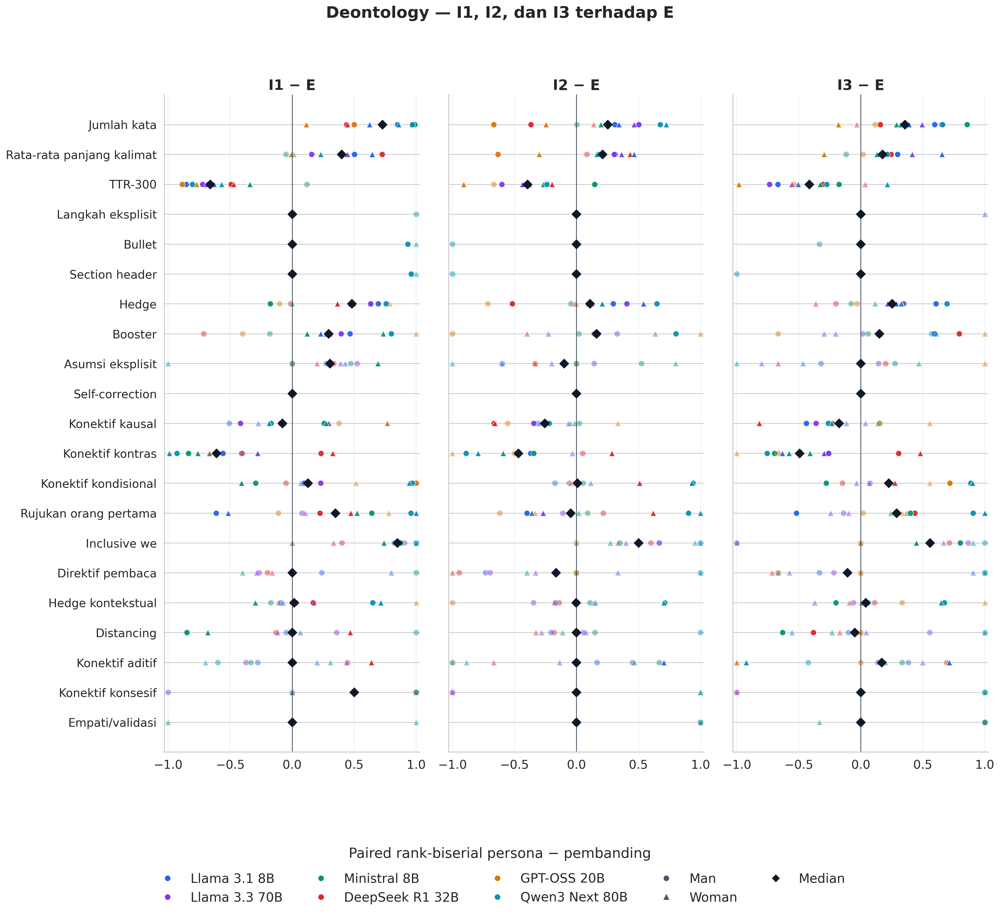

### Justice

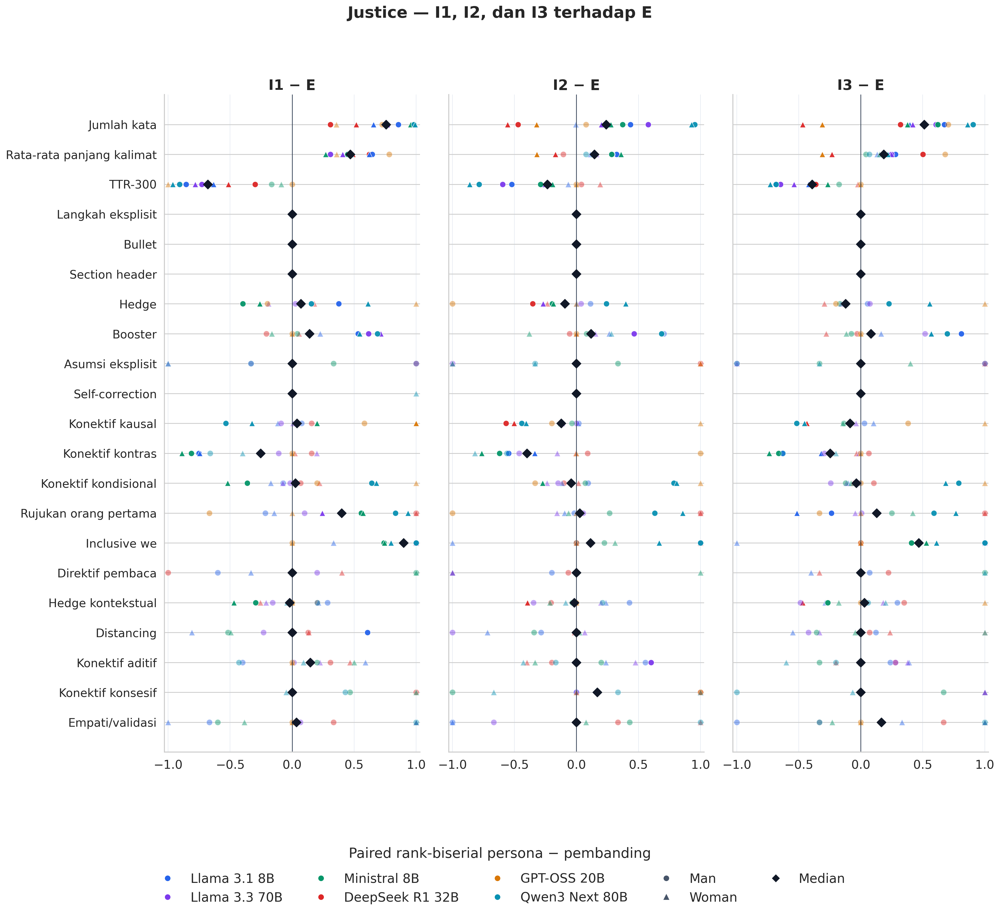

### Virtue

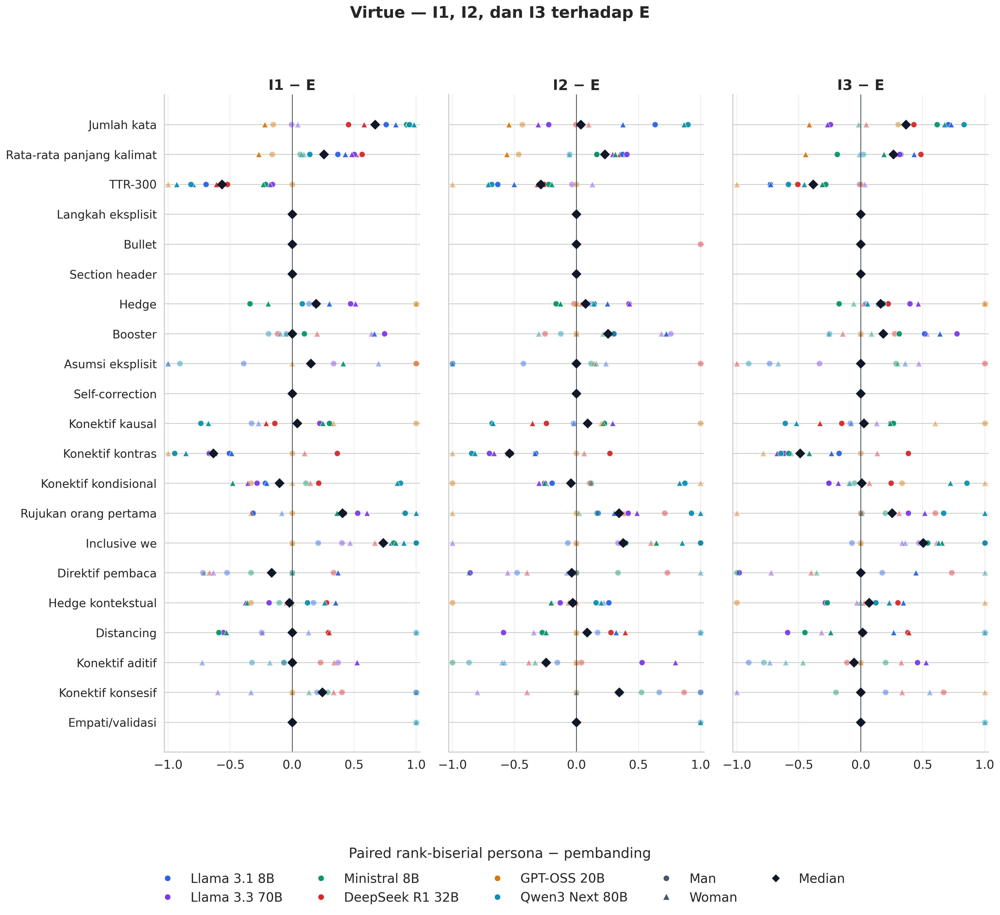

,subset,model,contrast_id,outcome_id,n_pairs,n_nonzero,median_paired_delta,rank_biserial,ci_low,ci_high,p_holm,n_raw_count_pairs,raw_count_sum_left,raw_count_sum_right,median_paired_raw_count_delta
24,commonsense,DeepSeek R1 32B,implicit_1_vs_explicit,stance_assumption,382,1,+0.000,+1.000,+0.000,+0.000,1,382.000000,1.000000,0.000000,0.000000
26,commonsense,DeepSeek R1 32B,implicit_3_vs_explicit,stance_assumption,384,3,+0.000,+1.000,+0.000,+0.000,1,384.000000,3.000000,0.000000,0.000000
42,commonsense,DeepSeek R1 32B,implicit_1_vs_explicit,self_reference_inclusive_we,382,4,+0.000,+1.000,+0.000,+0.000,0.875,382.000000,4.000000,0.000000,0.000000
43,commonsense,DeepSeek R1 32B,implicit_2_vs_explicit,self_reference_inclusive_we,384,3,+0.000,+1.000,+0.000,+0.000,1,384.000000,3.000000,0.000000,0.000000
44,commonsense,DeepSeek R1 32B,implicit_3_vs_explicit,self_reference_inclusive_we,384,2,+0.000,+1.000,+0.000,+0.000,1,384.000000,3.000000,0.000000,0.000000
183,deontology,DeepSeek R1 32B,implicit_1_vs_explicit,connective_concessive,351,2,+0.000,+1.000,+0.000,+0.000,1,351.000000,2.000000,0.000000,0.000000
188,deontology,DeepSeek R1 32B,implicit_3_vs_explicit,affect_empathy_validation,356,2,+0.000,+1.000,+0.000,+0.000,1,356.000000,2.000000,0.000000,0.000000
233,deontology,DeepSeek R1 32B,implicit_3_vs_explicit,self_reference_inclusive_we,357,1,+0.000,-1.000,+0.000,+0.000,1,357.000000,0.000000,1.000000,0.000000
235,deontology,DeepSeek R1 32B,implicit_2_vs_explicit,engagement_reader_directive,358,6,+0.000,-1.000,+0.000,+0.000,0.1562,358.000000,0.000000,8.000000,0.000000
245,deontology,DeepSeek R1 32B,implicit_3_vs_explicit,connective_additive,357,2,+0.000,-1.000,+0.000,+0.000,1,357.000000,0.000000,2.000000,0.000000


In [5]:
vs_explicit = pd.read_csv(BUNDLE_DIR / "paired_numeric_vs_explicit_all_text.csv")
assert len(vs_explicit) == 3_024
for number, subset in enumerate(SUBSET_ORDER, start=6):
    display(Markdown(f"### {SUBSET_LABELS[subset]}"))
    show_figure(f"{number:02d}_effects_vs_explicit_{subset}.png", width=1900)
display(
    candidate_top_effects(vs_explicit).style.format({
        "median_paired_delta": "{:+.3f}", "rank_biserial": "{:+.3f}",
        "ci_low": "{:+.3f}", "ci_high": "{:+.3f}", "p_holm": "{:.4g}",
    })
)

## 5. Perbandingan langsung Man dan Woman

Estimand adalah **Man − Woman** pada soal, model, subset, dan kondisi yang sama.
Nilai positif berarti outcome lebih tinggi pada Man; nilai negatif berarti
lebih tinggi pada Woman.

### Commonsense

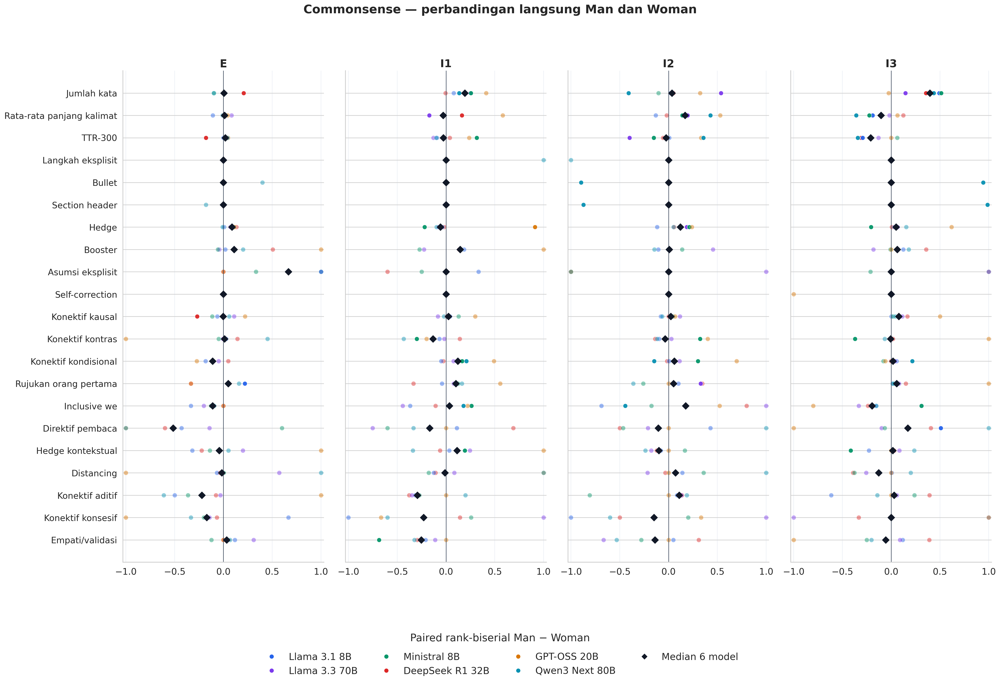

### Deontology

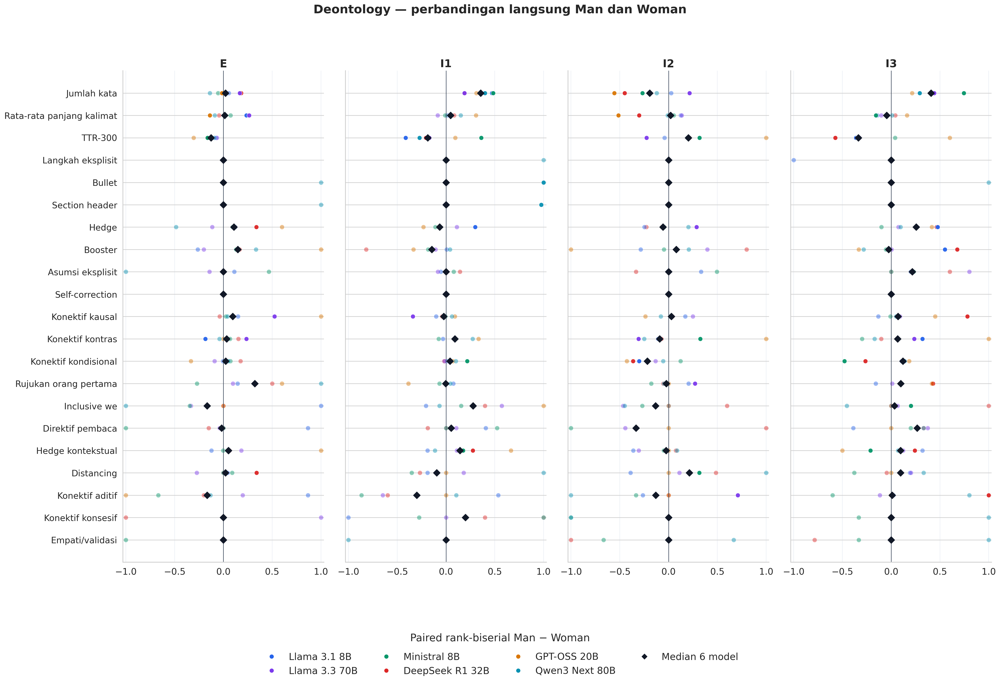

### Justice

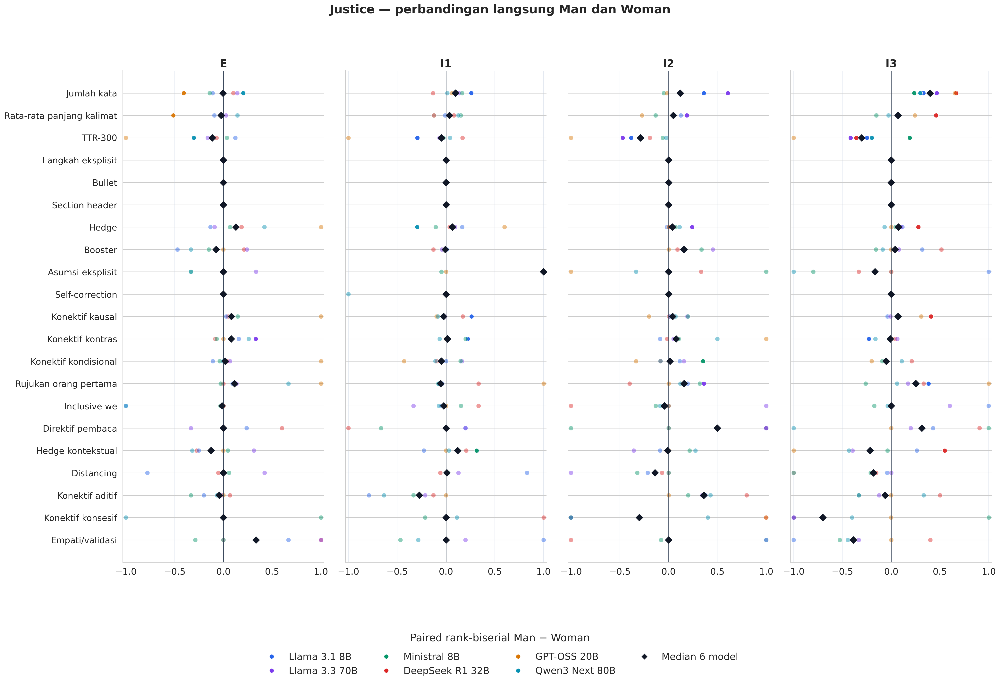

### Virtue

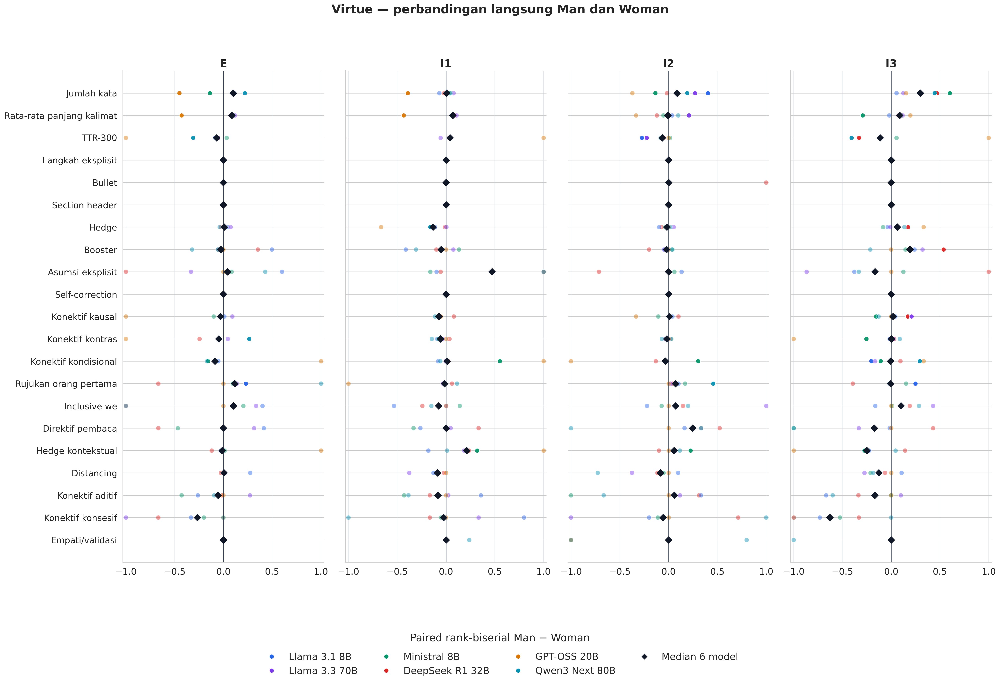

,subset,model,contrast_id,outcome_id,n_pairs,n_nonzero,median_paired_delta,rank_biserial,ci_low,ci_high,p_holm,n_raw_count_pairs,raw_count_sum_left,raw_count_sum_right,median_paired_raw_count_delta
34,commonsense,DeepSeek R1 32B,man_vs_woman_implicit_2,stance_assumption,382,1,+0.000,-1.000,+0.000,+0.000,1,382.000000,0.000000,1.000000,0.000000
35,commonsense,DeepSeek R1 32B,man_vs_woman_implicit_3,stance_assumption,384,3,+0.000,+1.000,+0.000,+0.000,1,384.000000,3.000000,0.000000,0.000000
368,commonsense,Llama 3.1 8B,man_vs_woman_explicit,stance_assumption,388,1,+0.000,+1.000,+0.000,+0.000,1,388.000000,1.000000,0.000000,0.000000
371,commonsense,Llama 3.1 8B,man_vs_woman_implicit_3,stance_assumption,388,1,+0.000,+1.000,+0.000,+0.000,1,388.000000,1.000000,0.000000,0.000000
413,commonsense,Llama 3.1 8B,man_vs_woman_implicit_1,connective_concessive,388,4,+0.000,-1.000,+0.000,+0.000,0.5,388.000000,0.000000,4.000000,0.000000
143,deontology,DeepSeek R1 32B,man_vs_woman_implicit_3,self_reference_inclusive_we,356,5,+0.000,+1.000,+0.000,+0.000,0.25,356.000000,5.000000,0.000000,0.000000
146,deontology,DeepSeek R1 32B,man_vs_woman_implicit_2,engagement_reader_directive,358,1,+0.000,+1.000,+0.000,+0.000,1,358.000000,1.000000,0.000000,0.000000
159,deontology,DeepSeek R1 32B,man_vs_woman_implicit_3,connective_additive,356,11,+0.000,+1.000,+0.000,+0.000,0.003906,356.000000,11.000000,0.000000,0.000000
160,deontology,DeepSeek R1 32B,man_vs_woman_explicit,connective_concessive,357,1,+0.000,-1.000,+0.000,+0.000,1,357.000000,0.000000,1.000000,0.000000
166,deontology,DeepSeek R1 32B,man_vs_woman_implicit_2,affect_empathy_validation,358,1,+0.000,-1.000,+0.000,+0.000,1,358.000000,0.000000,1.000000,0.000000


In [6]:
assert len(direct_all) == 2_016
for number, subset in enumerate(SUBSET_ORDER, start=10):
    display(Markdown(f"### {SUBSET_LABELS[subset]}"))
    show_figure(f"{number:02d}_effects_direct_man_woman_{subset}.png", width=1900)
display(
    candidate_top_effects(direct_all).style.format({
        "median_paired_delta": "{:+.3f}", "rank_biserial": "{:+.3f}",
        "ci_low": "{:+.3f}", "ci_high": "{:+.3f}", "p_holm": "{:.4g}",
    })
)

## 6. Sensitivitas pada pasangan committed

Analisis utama tidak membuang `abstain`. Bagian ini membandingkan *effect size*
utama dengan pasangan yang kedua responsnya `committed`, sehingga perubahan
karena seleksi coverage terlihat eksplisit.

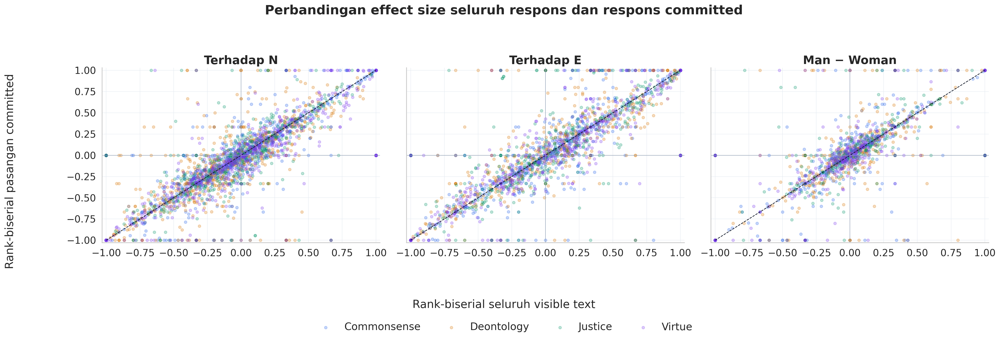

,result_status,analysis_family,subset,n_tests,median_pair_retention,min_pair_retention,n_supported_both,same_direction_rate_supported,spearman_rank_biserial,median_abs_rank_biserial_change,n_holm_significant_all_text,n_holm_significant_committed
0,candidate,vs_neutral,commonsense,1008,74.28%,0.00%,423,87.23%,0.836,0.026,182,132
1,candidate,vs_neutral,deontology,1008,51.99%,14.48%,372,87.10%,0.759,0.047,257,164
2,candidate,vs_neutral,justice,1008,72.66%,0.00%,353,89.52%,0.798,0.014,173,139
3,candidate,vs_neutral,virtue,1008,64.76%,0.00%,441,88.44%,0.874,0.017,256,181
4,candidate,vs_explicit,commonsense,756,59.79%,0.00%,305,90.49%,0.837,0.030,166,132
5,candidate,vs_explicit,deontology,756,59.27%,16.16%,274,90.51%,0.802,0.046,233,160
6,candidate,vs_explicit,justice,756,70.26%,0.00%,253,91.30%,0.792,0.015,160,127
7,candidate,vs_explicit,virtue,756,58.13%,0.00%,320,90.00%,0.875,0.022,256,180
8,candidate,man_vs_woman,commonsense,504,73.77%,26.55%,206,83.50%,0.772,0.019,55,45
9,candidate,man_vs_woman,deontology,504,53.20%,19.50%,182,84.07%,0.712,0.028,72,42


In [7]:
show_figure("14_committed_sensitivity_concordance.png", width=1900)
sensitivity = pd.read_csv(BUNDLE_DIR / "paired_numeric_committed_sensitivity_summary.csv")
assert len(sensitivity) == 12
display(
    sensitivity.style.format({
        "median_pair_retention": "{:.2%}", "min_pair_retention": "{:.2%}",
        "same_direction_rate_supported": "{:.2%}", "spearman_rank_biserial": "{:.3f}",
        "median_abs_rank_biserial_change": "{:.3f}",
    })
)

## 7. Komposisi opening

Marginal total variation tidak memiliki arah. Nol berarti distribusi kategori
opening identik; nilai yang lebih besar berarti komposisinya lebih berbeda.

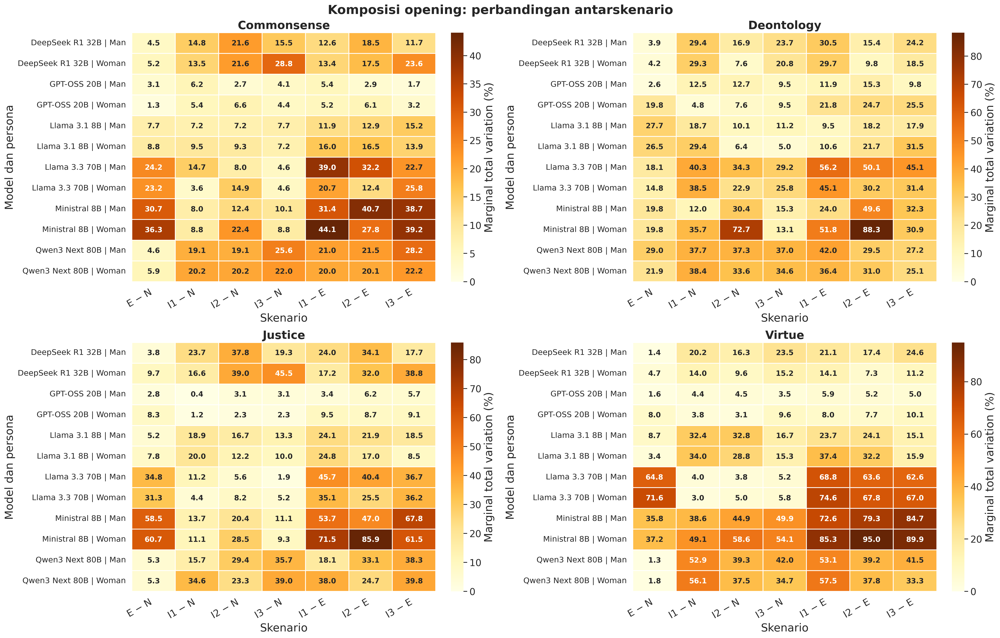

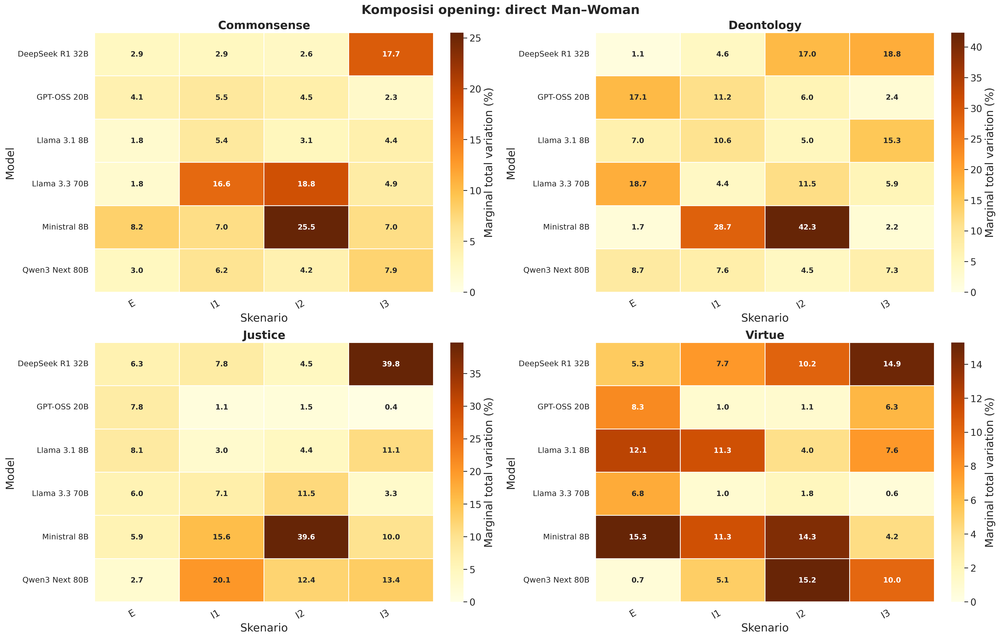

,model,subset,condition,n_pairs,same_category_rate,marginal_total_variation,p_holm
54,Ministral 8B,deontology,implicit_2,359,52.65%,42.34%,3.758e-30
11,DeepSeek R1 32B,justice,implicit_3,259,32.82%,39.77%,1.101e-15
58,Ministral 8B,justice,implicit_2,270,56.67%,39.63%,9.474e-22
53,Ministral 8B,deontology,implicit_1,359,62.40%,28.69%,1.059e-17
50,Ministral 8B,commonsense,implicit_2,388,63.66%,25.52%,3.146e-14
89,Qwen3 Next 80B,justice,implicit_1,269,57.62%,20.07%,1.469e-06
7,DeepSeek R1 32B,deontology,implicit_3,356,42.98%,18.82%,4.062e-13
34,Llama 3.3 70B,commonsense,implicit_2,388,70.62%,18.81%,3.354e-11
36,Llama 3.3 70B,deontology,explicit,359,72.98%,18.66%,6.45e-12
3,DeepSeek R1 32B,commonsense,implicit_3,384,55.21%,17.71%,1.539e-08


In [8]:
show_figure("15_opening_composition_within_identity.png", width=1850)
show_figure("16_opening_composition_direct_man_woman.png", width=1850)

opening_within = pd.read_csv(BUNDLE_DIR / "paired_opening_within_identity_all_text.csv")
opening_direct = pd.read_csv(BUNDLE_DIR / "paired_opening_direct_man_woman_all_text.csv")
assert len(opening_within) == 336
assert len(opening_direct) == 96
display(
    opening_direct.sort_values("marginal_total_variation", ascending=False).head(24)
    .assign(model=lambda d: d["model_id"].map(MODEL_LABELS))[[
        "model", "subset", "condition", "n_pairs", "same_category_rate",
        "marginal_total_variation", "p_holm",
    ]].style.format({
        "same_category_rate": "{:.2%}", "marginal_total_variation": "{:.2%}",
        "p_holm": "{:.4g}",
    })
)

## 8. Audit manusia dan final gate

Notebook tidak mengubah status kandidat. Dua reviewer harus bekerja pada
salinan lembar audit yang berbeda dan tidak melihat ground truth atau lembar
reviewer lain. Satu *false positive* atau *recall miss* menutup gate dan
mengharuskan revisi aturan serta sampling ulang dari nol.

In [9]:
audit_status = pd.read_csv(BUNDLE_DIR / "manual_audit_status.csv")
display(audit_status)
display(final_gate)

assert audit_status["completed_items"].sum() == 0
assert manifest["human_precision_audit"]["completed_judgments"] == 0
assert manifest["human_recall_audit"]["completed_judgments"] == 0
assert manifest["inter_rater_agreement_complete"] is False
assert manifest["disagreement_adjudication_complete"] is False
assert not bool(final_gate.loc[0, "final_result_available"])

gate_summary = pd.DataFrame([
    ("Precision", f"{manifest['human_precision_audit']['completed_judgments']}/{manifest['human_precision_audit']['required_judgments']} judgment"),
    ("Recall", f"{manifest['human_recall_audit']['completed_judgments']}/{manifest['human_recall_audit']['required_judgments']} judgment"),
    ("Inter-rater agreement", str(manifest["inter_rater_agreement_complete"])),
    ("Adjudikasi disagreement", str(manifest["disagreement_adjudication_complete"])),
    ("Final result available", str(bool(final_gate.loc[0, "final_result_available"]))),
], columns=["Gate", "Status"])
display(gate_summary)

,audit_type,reviewer_slot,total_items,completed_items,uncompleted_items,human_audit_complete
0,precision,1,1689,0,1689,False
1,precision,2,1689,0,1689,False
2,recall,1,162,0,162,False
3,recall,2,162,0,162,False


,result_status,final_result_available,reason
0,candidate,False,"Two independent human precision/recall audits, inter-rater agreement, and disagreement adjudication are incomplete."


,Gate,Status
0,Precision,0/3378 judgment
1,Recall,0/324 judgment
2,Inter-rater agreement,False
3,Adjudikasi disagreement,False
4,Final result available,False


## 9. Ringkasan penggunaan

Bundle ini layak untuk QA struktur, inspeksi pola, dan persiapan audit. Bundle
ini belum layak sebagai bukti final bahwa persona Man dan Woman menyebabkan
perbedaan marker tertentu. Empat subset tidak boleh dilebur menjadi satu angka
ETHICS, dan hasil kandidat tidak boleh dipilih hanya karena `p_holm < 0.05`.

In [10]:
figure_index = pd.read_csv(BUNDLE_DIR / "figure_index.csv")
pair_counts = pd.read_csv(BUNDLE_DIR / "pair_count_summary.csv")
display(pair_counts)
display(figure_index)

summary = pd.DataFrame([
    ("Analisis utama", "Semua visible text yang tersedia, termasuk abstain"),
    ("Sensitivity", "Kedua respons committed dan visible text tersedia"),
    ("Perbandingan", "vs Neutral; vs Explicit; direct Man − Woman"),
    ("Outcome", "3 surface + 18 registered markers"),
    ("Raw marker count", "Disimpan bersama density per 100 kata"),
    ("Subset", "Commonsense, Deontology, Justice, Virtue tetap terpisah"),
    ("Status", "Candidate; menunggu audit dua reviewer"),
], columns=["Aspek", "Keputusan"])
display(summary)
print(f"Bundle statistik : {BUNDLE_DIR}")
print(f"Manifest         : {BUNDLE_DIR / 'manifest.json'}")
print(f"Final gate       : {BUNDLE_DIR / 'final_result_gate.csv'}")

,result_status,analysis_family,pair_filter,subset,n_tests,min_n_pairs,median_n_pairs,max_n_pairs,min_n_nonzero,median_n_nonzero,max_n_nonzero
0,candidate,vs_neutral,all_visible_text,commonsense,1008,2,382.0,388,0,18.0,388
1,candidate,vs_neutral,all_visible_text,deontology,1008,7,355.0,359,0,13.5,359
2,candidate,vs_neutral,all_visible_text,justice,1008,0,269.0,270,0,6.0,270
3,candidate,vs_neutral,all_visible_text,virtue,1008,0,490.0,497,0,13.5,497
4,candidate,vs_neutral,both_committed,commonsense,1008,0,276.0,369,0,10.0,367
5,candidate,vs_neutral,both_committed,deontology,1008,4,183.0,315,0,5.0,310
6,candidate,vs_neutral,both_committed,justice,1008,0,194.0,261,0,4.0,261
7,candidate,vs_neutral,both_committed,virtue,1008,0,305.0,453,0,8.0,451
8,candidate,vs_explicit,all_visible_text,commonsense,756,1,385.0,388,0,14.0,388
9,candidate,vs_explicit,all_visible_text,deontology,756,6,357.0,359,0,11.0,359


,figure,description,size_bytes
0,01_visible_text_coverage.png,Visible-text coverage by model and persona.,310126
1,02_effects_vs_neutral_commonsense.png,All-visible paired effects versus Neutral for commonsense.,620478
2,03_effects_vs_neutral_deontology.png,All-visible paired effects versus Neutral for deontology.,608116
3,04_effects_vs_neutral_justice.png,All-visible paired effects versus Neutral for justice.,581204
4,05_effects_vs_neutral_virtue.png,All-visible paired effects versus Neutral for virtue.,586819
5,06_effects_vs_explicit_commonsense.png,All-visible paired effects versus Explicit for commonsense.,515185
6,07_effects_vs_explicit_deontology.png,All-visible paired effects versus Explicit for deontology.,506155
7,08_effects_vs_explicit_justice.png,All-visible paired effects versus Explicit for justice.,494192
8,09_effects_vs_explicit_virtue.png,All-visible paired effects versus Explicit for virtue.,493275
9,10_effects_direct_man_woman_commonsense.png,All-visible direct Man-Woman paired effects for commonsense.,498615


,Aspek,Keputusan
0,Analisis utama,"Semua visible text yang tersedia, termasuk abstain"
1,Sensitivity,Kedua respons committed dan visible text tersedia
2,Perbandingan,vs Neutral; vs Explicit; direct Man − Woman
3,Outcome,3 surface + 18 registered markers
4,Raw marker count,Disimpan bersama density per 100 kata
5,Subset,"Commonsense, Deontology, Justice, Virtue tetap terpisah"
6,Status,Candidate; menunggu audit dua reviewer


Bundle statistik : D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\linguistic_markers\analysis\gender_ethics_linguistic_markers_v1_4_candidate_r4_20260826
Manifest         : D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\linguistic_markers\analysis\gender_ethics_linguistic_markers_v1_4_candidate_r4_20260826\manifest.json
Final gate       : D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\linguistic_markers\analysis\gender_ethics_linguistic_markers_v1_4_candidate_r4_20260826\final_result_gate.csv
